In [ ]:
//SMS Spam Classification using SVM
Dataset: https://www.kaggle.com/datasets/shalmamuji/spam-email-classification

In [2]:
# Install required libraries
!pip -q install wordcloud nltk scikit-learn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
import re
import string
import nltk

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

nltk.download('stopwords')
nltk.download('wordnet')

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


In [6]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename, encoding="latin-1")

df = df[['email', 'label']]

df.columns = ['message', 'label']

print("Email dataset uploaded and loaded successfully!")
print("Total emails:", len(df))
print("Dataset columns:", df.columns.tolist())

Saving email_classification_dataset.csv to email_classification_dataset.csv
Email dataset uploaded and loaded successfully!
Total emails: 10000
Dataset columns: ['message', 'label']


In [7]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nClass distribution:")
print(df['label'].value_counts())

print("\nFirst 5 email records:")
print(df.head())

Dataset shape: (10000, 2)

Missing values:
message    0
label      0
dtype: int64

Duplicate records: 8223

Class distribution:
label
ham     8500
spam    1500
Name: count, dtype: int64

First 5 email records:
                                             message label
0  From: support@legitcompany.com\nSubject: Regar...   ham
1  From: noreply@softwareupdates.com\nSubject: We...   ham
2  From: noreply@softwareupdates.com\nSubject: Im...   ham
3  From: info@customerservice.co\nSubject: Team S...   ham
4  From: info@customerservice.co\nSubject: Team S...   ham


Average email length: 246.84
Average number of words: 37.1
Emails containing subject: 10000


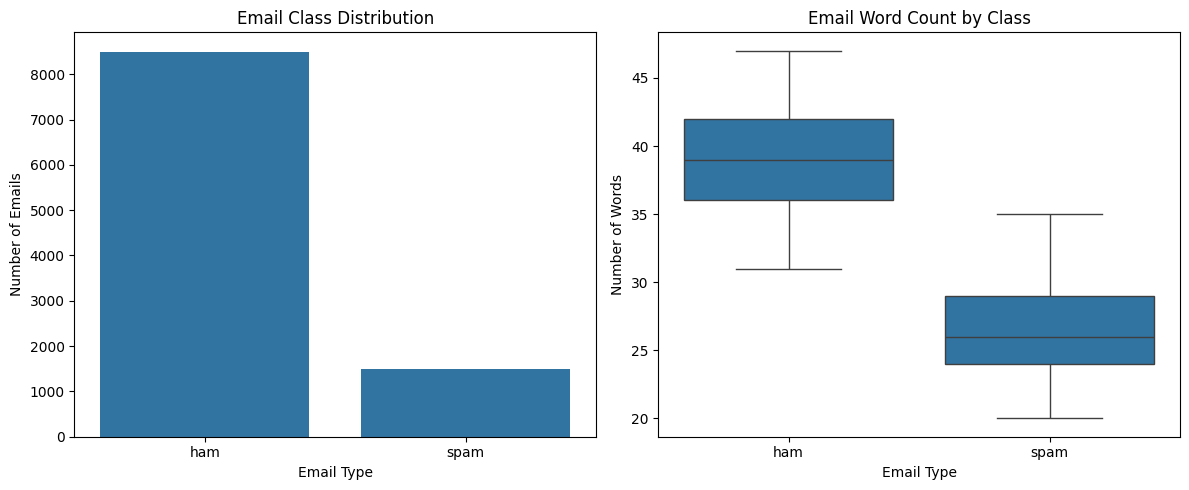

In [9]:
# Calculate basic email statistics
df['char_count'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()
df['line_count'] = df['message'].str.count('\n') + 1

# Check whether emails contain a subject line
df['has_subject'] = df['message'].str.contains(
    r'subject:',
    case=False,
    regex=True
)

print("Average email length:", round(df['char_count'].mean(), 2))
print("Average number of words:", round(df['word_count'].mean(), 2))
print("Emails containing subject:", df['has_subject'].sum())

# Visualize the data
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(data=df, x='label', ax=ax[0])
ax[0].set_title("Email Class Distribution")
ax[0].set_xlabel("Email Type")
ax[0].set_ylabel("Number of Emails")

sns.boxplot(data=df, x='label', y='word_count', ax=ax[1])
ax[1].set_title("Email Word Count by Class")
ax[1].set_xlabel("Email Type")
ax[1].set_ylabel("Number of Words")

plt.tight_layout()
plt.show()

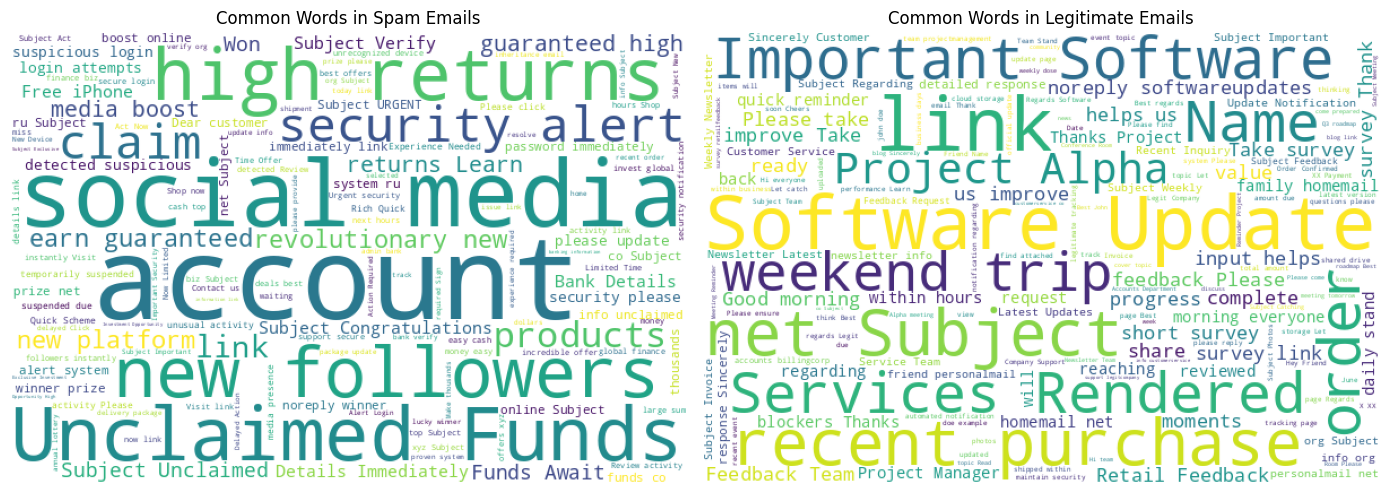

In [10]:
spam_text = ' '.join(df[df['label'] == 'spam']['message'])
ham_text = ' '.join(df[df['label'] == 'ham']['message'])

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
spam_cloud = WordCloud(
    width=600,
    height=400,
    background_color='white'
).generate(spam_text)

plt.imshow(spam_cloud)
plt.axis('off')
plt.title("Common Words in Spam Emails")

plt.subplot(1, 2, 2)
ham_cloud = WordCloud(
    width=600,
    height=400,
    background_color='white'
).generate(ham_text)

plt.imshow(ham_cloud)
plt.axis('off')
plt.title("Common Words in Legitimate Emails")

plt.tight_layout()
plt.show()

In [11]:
# Load English stopwords
stop_words = set(stopwords.words('english'))

# Create lemmatizer
lemm = WordNetLemmatizer()


def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove subject heading
    text = re.sub(r'\bsubject\s*:', ' ', text)

    # Remove numeric values
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    # Tokenize, remove stopwords and lemmatize
    tokens = [
        lemm.lemmatize(word)
        for word in text.split()
        if word not in stop_words
    ]

    # Join words back together
    text = ' '.join(tokens)

    # Normalize multiple spaces into one
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Remove duplicate emails
df = df.drop_duplicates()

# Remove rows with missing email or label
df = df.dropna(subset=['message', 'label'])

# Apply preprocessing
df['clean_message'] = df['message'].apply(clean_text)

# Convert labels to numerical values
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

print("Preprocessing completed successfully!")
print("Remaining records:", len(df))

df[['label', 'clean_message']].head()

Preprocessing completed successfully!
Remaining records: 1777


,label,clean_message
0,0,regarding recent inquiry thank reaching regard...
1,0,weekly newsletter latest update please find at...
2,0,important software update notification thank o...
3,0,team standup please find attached invoice serv...
4,0,team standup here weekly dose news update comm...


In [12]:
X = df['clean_message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training emails:", X_train.shape[0])
print("Testing emails:", X_test.shape[0])

Training emails: 1421
Testing emails: 356


In [13]:
pipeline = Pipeline([
    (
        'tfidf',
        TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )
    ),
    (
        'svm',
        LinearSVC()
    )
])

pipeline.fit(X_train, y_train)

pred = pipeline.predict(X_test)

print("Model training completed.")
print("Test predictions generated:", len(pred))

Model training completed.
Test predictions generated: 356


In [14]:
print("===== EMAIL SPAM CLASSIFIER RESULTS =====")

print("Accuracy :", round(accuracy_score(y_test, pred), 4))
print("Precision:", round(precision_score(y_test, pred), 4))
print("Recall   :", round(recall_score(y_test, pred), 4))
print("F1 Score :", round(f1_score(y_test, pred), 4))

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        pred,
        target_names=['Legitimate Email', 'Spam Email']
    )
)

===== EMAIL SPAM CLASSIFIER RESULTS =====
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Detailed Classification Report:
                  precision    recall  f1-score   support

Legitimate Email       1.00      1.00      1.00       200
      Spam Email       1.00      1.00      1.00       156

        accuracy                           1.00       356
       macro avg       1.00      1.00      1.00       356
    weighted avg       1.00      1.00      1.00       356



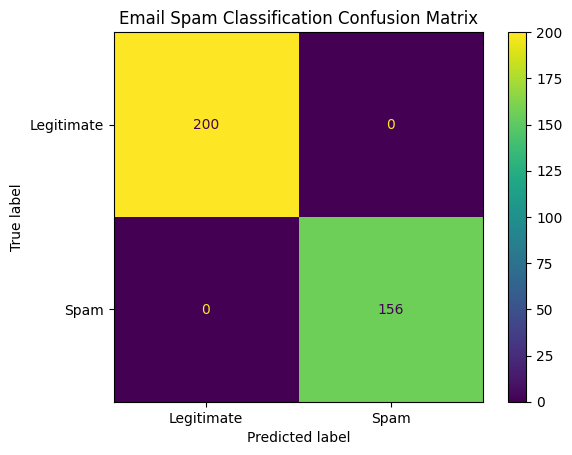

In [15]:
cm = confusion_matrix(y_test, pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legitimate', 'Spam']
)

disp.plot()
plt.title("Email Spam Classification Confusion Matrix")
plt.show()

In [16]:
param_grid = {
    'svm__C': [0.1, 1, 10]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Hyperparameter tuning completed.")
print("Best SVM parameter:", grid.best_params_)
print("Best cross-validation score:", round(grid.best_score_, 4))

Hyperparameter tuning completed.
Best SVM parameter: {'svm__C': 0.1}
Best cross-validation score: 1.0


In [17]:
scores = cross_val_score(
    grid.best_estimator_,
    df['clean_message'],
    df['label'],
    cv=5
)

print("Cross-validation accuracy for each fold:")
print(np.round(scores, 4))

print("\nAverage cross-validation accuracy:",
      round(scores.mean(), 4))

print("Standard deviation:",
      round(scores.std(), 4))

Cross-validation accuracy for each fold:
[1. 1. 1. 1. 1.]

Average cross-validation accuracy: 1.0
Standard deviation: 0.0


In [19]:
print("Normal Email:")
print(predict_spam(
    "Hi John, I wanted to remind you that our project meeting "
    "is scheduled for tomorrow at 3 PM. Please bring the updated report."
))

print("\nSpam Email:")
print(predict_spam(
    "Congratulations! You have won a $1000 cash prize. "
    "Click the link now to claim your reward."
))

Normal Email:
Legitimate Email

Spam Email:
Spam Email
